# Match segmentation and phases of play

Build frame features and an explicit tactical-state baseline, then compare with supplied interval labels.

Download the bounded real sample first with `python scripts/download_data.py` from the repository root. Run cells in order. Each notebook can start a fresh kernel. Only data ingestion and pitch drawing use shared helpers; calculations below use NumPy/pandas/SciPy directly. Raw files remain excluded from Git. The sample contains one partial first half, so supervised-model training requires additional labeled matches for meaningful evaluation.


In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'workshop.py').exists())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from workshop import load_data, pitch  # ingestion and drawing only; methods below are explicit
dataset, wide, tracking, metadata, events, phases, raw = load_data()
tracking = tracking.sort_values(['player_id','period_id','frame_id']).copy()
assert not tracking.duplicated(['period_id','frame_id','player_id']).any()
observed = tracking.dropna(subset=['x','y'])
frame_id = int(observed.groupby(['period_id','frame_id']).size().loc[lambda s:s.eq(22)].index[20][1])
snapshot = observed[observed.frame_id.eq(frame_id)].copy()
keepers = {str(p['id']) for p in metadata['players'] if 'goalkeeper' in p['player_role']['name'].lower()}
role_labels = {str(p['id']):p['player_role']['acronym'] for p in metadata['players']}
print('Real match 1925299; loaded frames:', wide.shape[0], '| illustrative frame:', frame_id)

Real match 1925299; loaded frames: 6153 | illustrative frame: 61


## Build interpretable frame-level features
Use team centroids, width, length, possession and a rolling trend in ball progress. Brisbane attacks left in this first-half sample; rotate both axes for its attack-right progress. In a full match derive orientation per period/team from metadata. These features support segmentation but do not uniquely define tactical phases.

In [2]:
shape=observed.groupby(['period_id','frame_id','team_id']).agg(cx=('x','mean'),cy=('y','mean'),xmin=('x','min'),xmax=('x','max'),ymin=('y','min'),ymax=('y','max'))
shape['width']=shape.ymax-shape.ymin;shape['length']=shape.xmax-shape.xmin
frame=wide[['period_id','frame_id','timestamp','ball_x','ball_y','ball_owning_team_id']].copy()
frame['seconds']=frame.timestamp.dt.total_seconds();frame=frame.sort_values(['period_id','frame_id'])
frame['sign']=np.where(frame.ball_owning_team_id.eq(1802),-1,1)
frame['attack_x']=frame.ball_x*frame.sign
new=(frame.period_id.ne(frame.period_id.shift())|frame.frame_id.diff().ne(1)|frame.ball_owning_team_id.ne(frame.ball_owning_team_id.shift()))
frame['possession_segment']=new.cumsum()
frame['possession_age']=frame.seconds-frame.groupby('possession_segment').seconds.transform('first')
frame['progress_speed']=frame.groupby('possession_segment').attack_x.diff()/frame.groupby('possession_segment').seconds.diff()
frame['progress_1s']=frame.groupby('possession_segment').progress_speed.transform(lambda s:s.rolling(10,min_periods=5).mean())
display(frame[['frame_id','attack_x','possession_age','progress_1s']].head(15))

,frame_id,attack_x,possession_age,progress_1s
0,40,-0.64,0.0,NaN
1,41,-1.10,0.1,NaN
2,42,-1.70,0.2,NaN
3,43,-2.36,0.3,NaN
4,44,-3.04,0.4,NaN
5,45,-3.69,0.5,-6.100000
6,46,-4.25,0.6,-6.016667
7,47,-4.76,0.7,-5.885714
8,48,-5.27,0.8,-5.787500
9,49,-5.75,0.9,-5.677778


## A transparent rule-based state classifier
Rules below are deliberately simple: a fast early advance is a transition candidate; otherwise classify by field zone. Values are teaching choices, not SkillCorner's production definitions. Invalid ball position or unknown possession yields an unknown state.

In [3]:
def rule_phase(row):
    if pd.isna(row.attack_x) or row.ball_owning_team_id not in [1802,871]:return 'unknown'
    if row.possession_age<8 and row.progress_1s>3:return 'transition candidate'
    if row.attack_x<-17.5:return 'deep circulation'
    if row.attack_x<17.5:return 'middle progression'
    return 'advanced possession'
frame['raw_phase']=frame.apply(rule_phase,axis=1)
# Confirm three consecutive labels causally; restart when possession/coverage changes.
def smooth_states(g):
    current='unknown';pending=None;n=0;output=[]
    for label in g.raw_phase:
        n=n+1 if label==pending else 1;pending=label
        if n>=3:current=label
        output.append(current)
    return pd.Series(output,index=g.index)
frame['phase']=pd.concat([smooth_states(g) for _,g in frame.groupby('possession_segment')]).sort_index()
breaks=frame.phase.ne(frame.phase.shift())|new
intervals=frame.groupby(breaks.cumsum()).agg(period=('period_id','first'),start=('seconds','min'),end=('seconds','max'),phase=('phase','first'),n=('frame_id','size'))
intervals['duration_s']=intervals.end-intervals.start+.1
display(intervals.head(12))

,period,start,end,phase,n,duration_s
1,1,3.0,3.1,unknown,2,0.2
2,1,3.2,5.2,middle progression,21,2.1
3,1,5.3,8.5,transition candidate,33,3.3
4,1,8.6,10.8,advanced possession,23,2.3
5,1,10.9,11.1,transition candidate,3,0.3
6,1,11.2,14.5,advanced possession,34,3.4
7,1,14.6,29.6,middle progression,151,15.1
8,1,29.7,29.8,unknown,2,0.2
9,1,29.9,30.3,middle progression,5,0.5
10,1,30.4,33.7,transition candidate,34,3.4


## Interval join to provider phases
Keep period and inclusive frame boundaries. Inspect overlaps rather than silently selecting one phase. Our rule taxonomy differs from the provider taxonomy, so a diagonal confusion-matrix interpretation would be misleading without a reviewed mapping.

provider_matches
1    5103
0    1015
2      35
Name: frames, dtype: int64

provider_phase,build_up,chaotic,create,direct,finish,quick_break,set_play,transition
phase,,,,,,,,
advanced possession,0,32,13,44,840,75,38,56
deep circulation,726,121,244,45,0,0,0,12
middle progression,1,20,1675,128,280,0,0,50
transition candidate,50,74,160,88,180,21,0,94
unknown,8,14,20,2,16,4,3,4


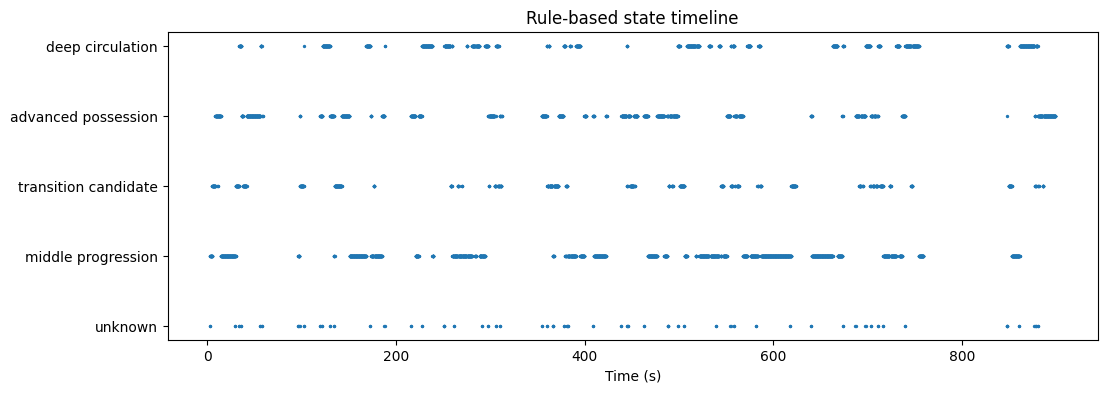

In [4]:
frame['provider_phase']=None;frame['provider_matches']=0
for r in phases.itertuples():
    mask=frame.period_id.eq(r.period)&frame.frame_id.between(r.frame_start,r.frame_end)&frame.ball_owning_team_id.eq(r.team_in_possession_id)
    frame.loc[mask,'provider_matches']+=1
    frame.loc[mask,'provider_phase']=r.team_in_possession_phase_type
display(frame.provider_matches.value_counts().rename('frames'))
display(pd.crosstab(frame.phase,frame.provider_phase))
fig,ax=plt.subplots(figsize=(12,4))
labels=list(frame.phase.unique());mapping={v:i for i,v in enumerate(labels)}
ax.scatter(frame.seconds,frame.phase.map(mapping),s=2);ax.set(yticks=range(len(labels)),yticklabels=labels,xlabel='Time (s)',title='Rule-based state timeline');plt.show()

**Next step:** learn a classifier or a sequence model on reviewed phases, using match-level splits and boundary-tolerant evaluation. Hysteresis reduces flicker but introduces detection delay. Possession changes, dead-ball states and camera gaps need explicit treatment. [SkillCorner data and labels](https://github.com/SkillCorner/opendata).